# Laikipia farm digitisation: train and retrain the model

Run the cells **top to bottom**. Each step says what it does and what to look at.

```
fetch Sentinel-2  ->  labels from YOUR polygons  ->  train U-Net  ->  evaluate on unseen blocks
                                                                         |
   corrected polygons from Google Earth Pro  <-  predict new area  <-----+
          \_____________________  retrain (fine-tune)  ___________________/
```

Parts: **A** setup and data, **B** train, **C** evaluate, **D** predict, **E** retrain with new images.

## A. Setup

In [1]:
import os, sys, json, shutil
from pathlib import Path
project_candidates = [Path.cwd(), Path.cwd() / "laikipia-farm-mapper"]
if Path.cwd().name == "notebooks":
    project_candidates.insert(0, Path.cwd().parent)
project_dir = next((p for p in project_candidates if (p / "farmmap").is_dir()), None)
if project_dir is None:
    raise RuntimeError("Could not find the project folder containing the farmmap package")
os.chdir(project_dir)
sys.path.insert(0, str(project_dir))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio, geopandas as gpd
from rasterio.enums import Resampling

from farmmap.config import load_config
from farmmap.model import pick_device

cfg = load_config("config.yaml")
print("Project folder:", cfg.root)
print("Compute device:", pick_device(cfg.train.device), "(cpu is fine, just slower)")

Project folder: /home/sfg/Farm_Digitisation/laikipia-farm-mapper
Compute device: cpu (cpu is fine, just slower)


### A1. The area to map, and your farm polygons
- **Area:** the Laikipia County boundary (downloaded once from open data).
- **Farm polygons:** your Google Earth Pro file (`Digitized - Laikipia_Farms_*.kmz`) in `data/labels/manual/`. Every polygon becomes a training label, so their quality sets the ceiling for the model.
- Parcels flagged in the file's `QA_FLAG` column (duplicate labels, overlaps) are **ignored**, not learned. Settings: `reference.filters` in `config.yaml`.

Laikipia County: 9,691 km2
{'n_polygons_total': 12448, 'n_polygons_used': 12375, 'area_ha_p10': 0.12, 'area_ha_median': 0.46, 'area_ha_p90': 2.25, 'share_under_5_px_wide': 0.28, 'share_under_10_px_wide': 0.74, 'median_side_px': 6.8}



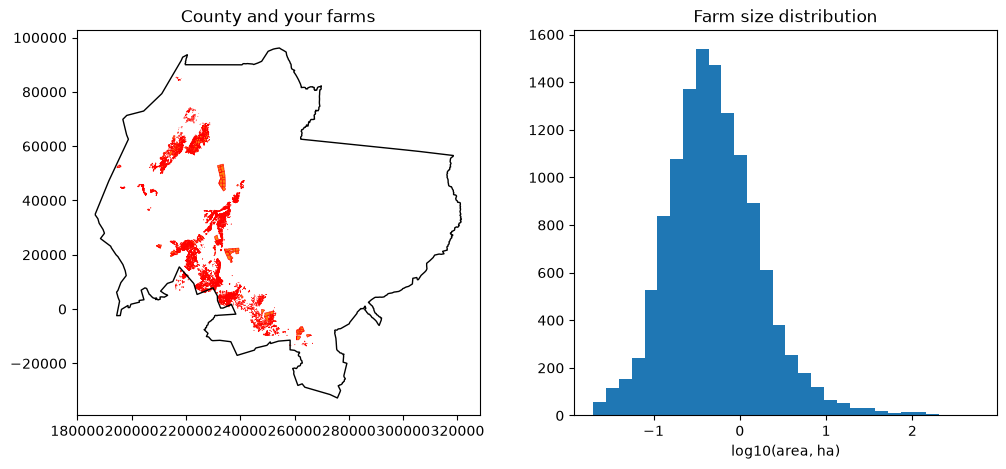

In [2]:
from farmmap.county import load_county
from farmmap.reference import load_reference, size_report, resolution_warning

county = load_county(cfg)
print(f"{cfg.aoi.county_name} County: {county.area.iloc[0]/1e6:,.0f} km2")

try:
    ref = load_reference(cfg)
except ValueError as e:
    ref = None
    print("\nSTOP:", e)

fig, ax = plt.subplots(1, 2 if ref is not None else 1, figsize=(12, 5), squeeze=False)
county.boundary.plot(ax=ax[0, 0], color="k", linewidth=1)
ax[0, 0].set_title("County" + (" and your farms" if ref is not None else ""))
if ref is not None:
    ref.plot(ax=ax[0, 0], facecolor="tab:orange", edgecolor="red", linewidth=0.4)
    rep = size_report(ref, cfg.project.resolution_m)
    print(rep)
    warn = resolution_warning(rep, cfg.project.resolution_m)
    if warn: print("\nWARNING:", warn)
    ax[0, 1].hist(np.log10(ref.area / 1e4), bins=30)
    ax[0, 1].set_xlabel("log10(area, ha)"); ax[0, 1].set_title("Farm size distribution")
plt.show()
assert ref is not None, "Add your farm polygons to data/labels/manual/ and re-run this cell."

### A2. Optional: change settings for this run
Everything lives in `config.yaml`; override here for a quick experiment. For a first run keep the pilot `bbox` small.

In [3]:
# Download area. Default is the densest part of your digitised farms (~8,000 parcels).
# cfg.imagery.bbox = [36.45, 0.00, 36.75, 0.30]   # [min_lon, min_lat, max_lon, max_lat]; None = whole county
# cfg.reference.filters["SOURCE"] = ["Digitized"]  # train only on parcels traced from imagery
# cfg.train.epochs = 10                            # shorter run to test the setup
# cfg.model.encoder = "resnet34"                   # larger model, slower on CPU
print("bbox:", cfg.imagery.bbox, "| filters:", cfg.reference.filters, "| epochs:", cfg.train.epochs)

bbox: [36.45, 0.0, 36.75, 0.3] | filters: {'QA_FLAG': ['OK']} | epochs: 20


### A3. How big is the download?

In [4]:
from farmmap.imagery import estimate
print(estimate(cfg))        # chunks_to_download skips chunks that are outside the county

{'width_px': 3342, 'height_px': 3320, 'chunks_total': 16, 'chunks_to_download': 16, 'area_km2': 1109}


### A4. Extract the satellite images
Builds a cloud-free median composite of the least cloudy Sentinel-2 scenes from the free Planetary Computer.
**Resumable:** if the connection drops, run the cell again and finished chunks are skipped.

In [5]:
from farmmap.imagery import fetch_composite
img_path = fetch_composite(cfg)
print(img_path)

Composite grid 3342x3320px, 16 chunks (8 already done)
  chunk 9/16 written
  chunk 10/16 written
  chunk 11/16 written
  chunk 12/16 written
  chunk 13/16 written
  chunk 14/16 written
  chunk 15/16 written
  chunk 16/16 written
/home/sfg/Farm_Digitisation/laikipia-farm-mapper/data/imagery/laikipia_s2.tif


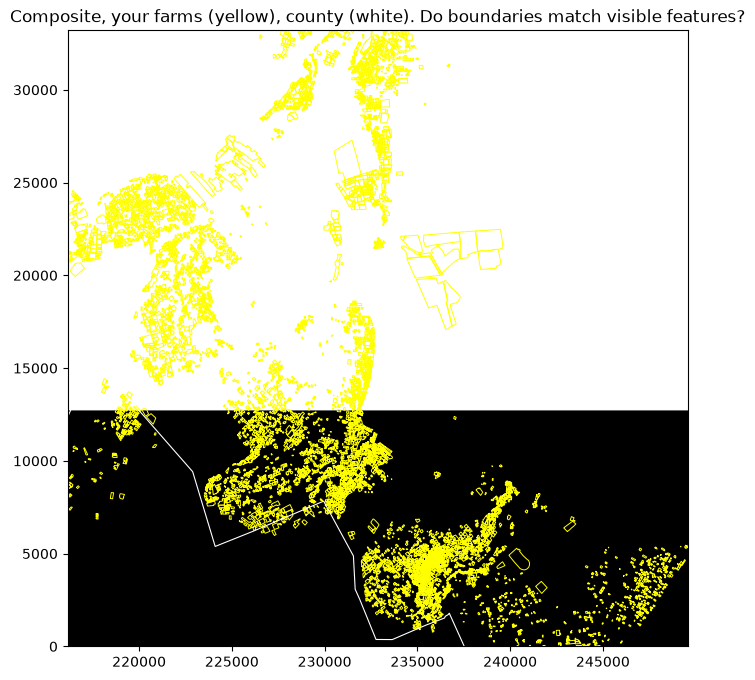

In [6]:
def rgb_preview(path, max_px=1200):
    with rasterio.open(path) as src:
        s = max(1, max(src.width, src.height) // max_px)
        d = src.read([3, 2, 1], out_shape=(3, src.height // s, src.width // s),
                     resampling=Resampling.average).astype("float32")
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
        crs = src.crs
    valid = (d > 0).all(0)
    lo, hi = np.percentile(d[:, valid], (2, 98)) if valid.any() else (0, 1)
    rgb = np.clip((d - lo) / (hi - lo + 1e-6), 0, 1).transpose(1, 2, 0)
    rgb[~valid] = 1
    return rgb, extent, crs

rgb, extent, crs = rgb_preview(img_path)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(rgb, extent=extent)
ref.to_crs(crs).boundary.plot(ax=ax, color="yellow", linewidth=0.7)
ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
county.to_crs(crs).boundary.plot(ax=ax, color="white", linewidth=0.8)
ax.set_title("Composite, your farms (yellow), county (white). Do boundaries match visible features?")
plt.show()

### A4b. Do your outlines sit on the imagery? (registration check)
Your file has two kinds of parcels: **Digitized** (traced on imagery) and **Scheme layer** (taken from scheme plans). Plan-derived outlines are often shifted from where the fence is on the image. A shift of even 2-3 pixels (20-30 m) teaches the model the wrong boundary.

For each source this measures image edge strength along the outlines after shifting them by up to 4 px. **Best shift should be (0, 0).** If one source clearly prefers another shift, or its contrast at zero shift is ~1.0 (no better than random), exclude it: `cfg.reference.filters["SOURCE"] = ["Digitized"]`, then run A5 again.

In [7]:
from farmmap.diagnostics import registration_check
reg = registration_check(cfg, img_path)
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "grid"} for k, v in reg.items()}).T

  Digitized: contrast 6.747 at 0 shift, best shift (-40, -20) m
  Scheme layer: contrast 0.527 at 0 shift, best shift (-40, -30) m


,n_outline_px,contrast_at_zero_shift,best_shift_px_east_south,best_shift_m,contrast_at_best_shift
Digitized,4452,6.747,"(-4, -2)","(-40, -20)",11.949
Scheme layer,119952,0.527,"(-4, -3)","(-40, -30)",1.337


### A5. Build training labels from your polygons
Each pixel becomes **0 background / 1 farm interior / 2 farm boundary** (255 = ignore: no imagery or far from any polygon).
This step is repeated whenever you add polygons or images (section E).

In [8]:
from farmmap.pipeline import prepare_training_data
scenes = prepare_training_data(cfg)
for s in scenes: print(s["name"], "->", s["labels"].name)

Reference farms: {'n_polygons_total': 12448, 'n_polygons_used': 12375, 'area_ha_p10': 0.12, 'area_ha_median': 0.46, 'area_ha_p90': 2.25, 'share_under_5_px_wide': 0.28, 'share_under_10_px_wide': 0.74, 'median_side_px': 6.8}
Rasterising reference polygons for scene 'laikipia_s2' ...
  labels 4/4
laikipia_s2 -> laikipia_s2_labels.tif


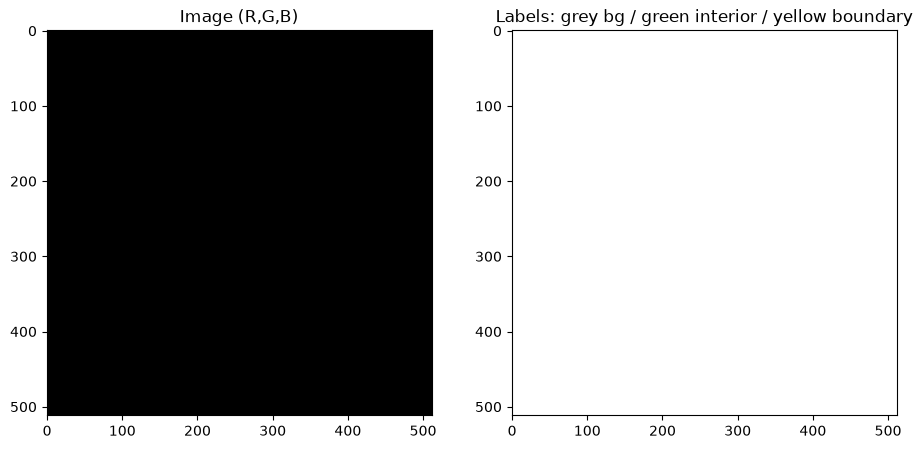

In [9]:
# Look at a sample: image and labels
s0 = scenes[0]
with rasterio.open(s0["imagery"]) as si, rasterio.open(s0["labels"]) as sl:
    r, c = si.height // 2 - 256, si.width // 2 - 256
    win = rasterio.windows.Window(max(c, 0), max(r, 0), 512, 512)
    im = si.read([3, 2, 1], window=win).astype("float32"); lb = sl.read(1, window=win)
im = np.clip(im / max(np.percentile(im[im > 0], 98), 1), 0, 1).transpose(1, 2, 0) if (im > 0).any() else im.transpose(1, 2, 0)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(im); ax[0].set_title("Image (R,G,B)")
cmap = plt.matplotlib.colors.ListedColormap(["#444444", "#4caf50", "#ffeb3b"])
ax[1].imshow(np.where(lb == 255, np.nan, lb), cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
ax[1].set_title("Labels: grey bg / green interior / yellow boundary"); plt.show()

### A6. Train / validation / test split
Whole 5 km blocks are held out, so the test score measures performance on **places the model has never seen**.
The assignment is saved in `data/labels/split.json` and never changes, so later models are scored on the same test blocks.

In [10]:
from farmmap.data import load_or_create_split, split_blocks
split = load_or_create_split(cfg, scenes)
for name in ("train", "val", "test"):
    print(name, len(split_blocks(split, name)), "blocks")

train 7 blocks
val 2 blocks
test 2 blocks


## B. Train the model

**Architecture:** a U-Net (encoder `resnet18`, ImageNet-pretrained) that reads the 6 Sentinel-2 bands + NDVI and predicts 3 classes per pixel.
Predicting the **boundary** as its own class is what lets us cut touching farms apart into separate polygons later.

**Loss:** class-weighted cross-entropy + Dice (boundary pixels are rare, so they are up-weighted).

In [11]:
from farmmap.data import ensure_norm, n_channels
from farmmap.model import build_model

norm = ensure_norm(cfg, scenes[0]["imagery"])
net = build_model(cfg.model.encoder, n_channels(norm), encoder_weights=None)
print(f"input channels: {n_channels(norm)} | parameters: {sum(p.numel() for p in net.parameters())/1e6:.1f} M")
del net

/home/sfg/Farm_Digitisation/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


input channels: 7 | parameters: 14.3 M


### B0. Sanity check BEFORE training (2-5 minutes)
Tells you whether training can work at all, so you do not spend hours on a run that cannot improve:
1. **Imagery statistics**: catches empty, constant or saturated composites.
2. **Model-free baseline**: can a simple per-pixel classifier separate interior / boundary / background? If it cannot, no neural network will with this imagery and these labels.
3. **Memorise-one-batch test**: the network must be able to drive the loss down on a single batch. If it cannot, there is a bug.

Read the **VERDICT** line it prints.

In [ ]:
from farmmap.diagnostics import diagnose
diag = diagnose(cfg, scenes)

### B1. Run training
Prints one line per epoch and saves the **best** epoch (by mean IoU of interior + boundary on validation blocks) to
`data/models/unet_best.pt`. On a CPU laptop expect a few minutes per epoch with the default settings.
Training stops early when validation stops improving. Interrupt the kernel to stop; the best checkpoint so far is kept.

In [12]:
from farmmap.train import train
result = train(cfg, scenes)          # from scratch
print("Best epoch:", result["best"].get("epoch"), "| score:", round(result["best"].get("score", 0), 3))
print("Checkpoint:", result["checkpoint"])

Blocks: train=7 val=2 test=2; device=cpu


/home/sfg/Farm_Digitisation/laikipia-farm-mapper/farmmap/train.py:132: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  run += float(loss)


epoch 01/20 train_loss=1.287 val_loss=1.098 IoU interior=0.000 boundary=0.000 (284.2s)
epoch 02/20 train_loss=1.259 val_loss=1.121 IoU interior=0.000 boundary=0.000 (241.0s)
epoch 03/20 train_loss=1.241 val_loss=1.114 IoU interior=0.000 boundary=0.000 (283.5s)
epoch 04/20 train_loss=1.251 val_loss=1.132 IoU interior=0.000 boundary=0.000 (254.5s)
epoch 05/20 train_loss=1.255 val_loss=1.117 IoU interior=0.000 boundary=0.000 (275.9s)
epoch 06/20 train_loss=1.238 val_loss=1.096 IoU interior=0.000 boundary=0.000 (260.6s)
epoch 07/20 train_loss=1.238 val_loss=1.088 IoU interior=0.000 boundary=0.000 (252.4s)
epoch 08/20 train_loss=1.242 val_loss=1.093 IoU interior=0.000 boundary=0.000 (233.6s)
epoch 09/20 train_loss=1.254 val_loss=1.110 IoU interior=0.000 boundary=0.000 (234.0s)
Early stop: no improvement for 8 epochs.
Best epoch: 1 | score: 0.0
Checkpoint: /home/sfg/Farm_Digitisation/laikipia-farm-mapper/data/models/unet_best.pt


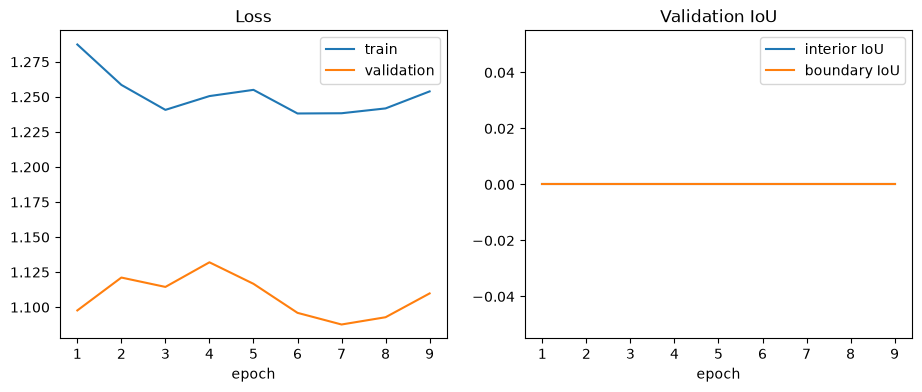

In [13]:
h = pd.read_csv(result["history_csv"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.iou_interior, label="interior IoU"); ax[1].plot(h.epoch, h.iou_boundary, label="boundary IoU")
ax[1].set_title("Validation IoU"); ax[1].set_xlabel("epoch"); ax[1].legend(); plt.show()

## C. Evaluate on unseen test blocks
Interpretation guide:
- **iou_interior**: how well farm *areas* are found.
- **boundary_f1** (within +/-20 m): how well farm *edges* are found. Expect this to be the weak point wherever no fence, road or land-use change exists.
- **farm_recall / farm_precision** (IoU >= 0.5): the fraction of your polygons recovered, and the fraction of predicted polygons that are right.

In [14]:
from farmmap.evaluate import evaluate
metrics_v1 = evaluate(cfg, scenes)
pd.Series(metrics_v1).to_frame("v1")

,v1
split,test
n_blocks,2
checkpoint,/home/sfg/Farm_Digitisation/laikipia-farm-mapp...
iou_background,0.691239
iou_interior,0.0
iou_boundary,0.0
boundary_precision,0.0
boundary_recall,0.0
boundary_f1,0.0
boundary_tolerance_m,20


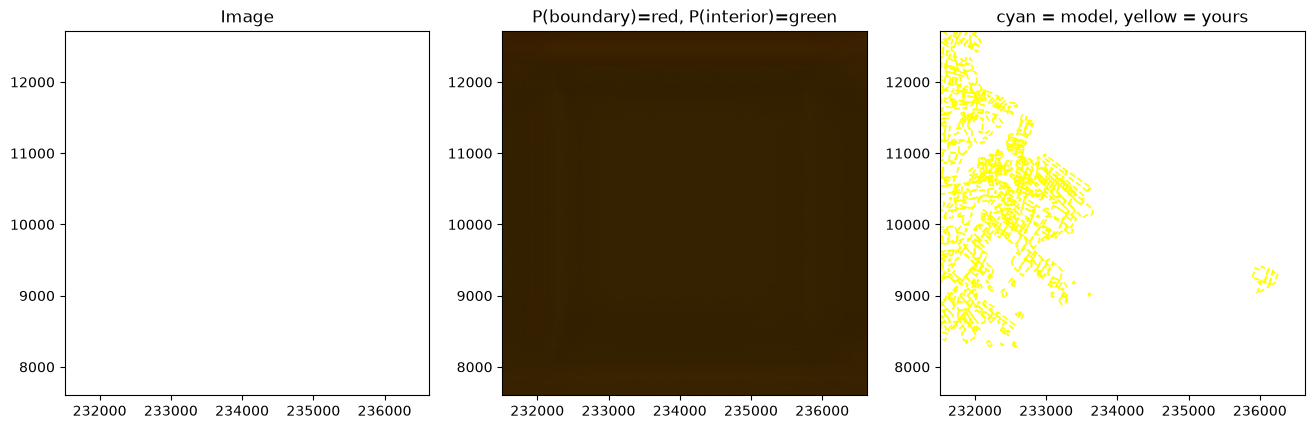

In [15]:
# Visual check on one test block: image, probabilities, predicted vs your polygons
from farmmap.data import block_window
from farmmap.predict import predict_raster
from farmmap.polygonize import polygonize_probs
import tempfile

test_blocks = split_blocks(split, "test")
b = test_blocks[0]
scene = next(s for s in scenes if s["name"] == b["scene"])
win = block_window(b)
with tempfile.TemporaryDirectory() as tmp:
    pr = predict_raster(cfg, scene["imagery"], None, Path(tmp) / "p.tif", [win], progress=lambda *_: None)
    with rasterio.open(pr) as sp, rasterio.open(scene["imagery"]) as si:
        probs = sp.read(window=win) / 255.0
        rgbw = si.read([3, 2, 1], window=win).astype("float32")
        tr = si.window_transform(win)
    polys = polygonize_probs(cfg, pr, progress=lambda *_: None)
rgbw = np.clip(rgbw / max(np.percentile(rgbw[rgbw > 0], 98), 1), 0, 1).transpose(1, 2, 0)
ext = (tr.c, tr.c + tr.a * win.width, tr.f + tr.e * win.height, tr.f)
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].imshow(rgbw, extent=ext); ax[0].set_title("Image")
ax[1].imshow(np.dstack([probs[2], probs[1], probs[0] * 0]), extent=ext); ax[1].set_title("P(boundary)=red, P(interior)=green")
ax[2].imshow(rgbw, extent=ext)
if len(polys):
    polys.boundary.plot(ax=ax[2], color="cyan", linewidth=1.2)
load_reference(cfg, crs=polys.crs).boundary.plot(ax=ax[2], color="yellow", linewidth=1.2, linestyle="--")
ax[2].set_xlim(ext[0], ext[1]); ax[2].set_ylim(ext[2], ext[3]); ax[2].set_title("cyan = model, yellow = yours")
plt.show()

## D. Use the model: image -> polygons -> Google Earth Pro

Writes a `.kmz` (open in Google Earth Pro), a `.gpkg` (QGIS) and the probability raster to `outputs/<name>/`.

To map the **whole county** later: `python -m farmmap predict --county` (downloads the county composite first; large).

In [16]:
from farmmap.pipeline import predict_area
res = predict_area(cfg, scenes[0]["imagery"], "pilot")
print(len(res["frame"]), "farms")
print("Open in Google Earth Pro:", res["kmz"])
res["frame"].head()

  predicted 20/49 tiles
  predicted 40/49 tiles
  predicted 49/49 tiles
Extracting farm polygons ...
0 farms
Open in Google Earth Pro: /home/sfg/Farm_Digitisation/laikipia-farm-mapper/outputs/pilot/laikipia_farm_polygons_pilot.kmz


,farm_id,area_ha,confidence,geometry


## E. Retrain with new images to get a better model

1. **Extract images** for areas where the model is weak or that you want to add (cell E1).
2. **Predict** there and open the KMZ in Google Earth Pro on top of the imagery.
3. **Correct / add polygons** exactly as you already do. Save as KML or KMZ into `data/labels/manual/`.
   - Digitise *whole* farms and be consistent about what counts as a boundary.
   - A polygon you draw **replaces** any earlier polygon it covers by more than half.
   - Areas with no polygons nearby are ignored, not treated as "no farms".
4. **Fine-tune** from the current model on all scenes (cell E2). It keeps what it learned and adapts to your corrections.
5. **Compare** old and new on the *same* test blocks and keep the new model only if it is better (cells E3 and E4).

In [ ]:
# E1. Extract a new area as an extra training scene (any bbox [min_lon, min_lat, max_lon, max_lat]
#     or aoi_path="my_area.kml"; the whole county is aoi_path=county_path(cfg)). It is saved in data/imagery/ and automatically used for training.
from farmmap.imagery import fetch_composite

NEW_NAME = "area_2"
NEW_BBOX = [36.95, -0.05, 37.10, 0.10]
new_img = fetch_composite(cfg, out_path=cfg.path(cfg.imagery.dir) / f"{NEW_NAME}.tif", bbox=NEW_BBOX)
new_pred = predict_area(cfg, new_img, NEW_NAME)
print("Review and correct in Google Earth Pro:", new_pred["kmz"])
print("Then save your corrected polygons into:", cfg.path("data/labels/manual"))

Composite grid 1671x1661px, 4 chunks (0 already done)
  chunk 1/4 written
  chunk 2/4 written


In [ ]:
# E2. After saving corrections into data/labels/manual/ : rebuild labels for ALL scenes and fine-tune.
scenes = prepare_training_data(cfg)

v1 = cfg.path(cfg.model.checkpoint)          # current model
v2 = cfg.path("data/models/unet_v2.pt")      # new model (kept separate until we compare)
result2 = train(cfg, scenes, init_checkpoint=v1, out_checkpoint=v2, epochs=15)
print("Best epoch:", result2["best"].get("epoch"), "| score:", round(result2["best"].get("score", 0), 3))

In [ ]:
# E3. Compare v1 and v2 on the same held-out test blocks
m1 = evaluate(cfg, scenes, checkpoint=v1)
m2 = evaluate(cfg, scenes, checkpoint=v2)
table = pd.DataFrame({"v1": m1, "v2": m2}).drop(["split", "checkpoint"])
table

In [ ]:
# E4. Promote v2 only if it is better. The old model is backed up first.
PROMOTE = False        # <- set to True after looking at the table above
if PROMOTE:
    shutil.copy(v1, v1.with_name("unet_v1_backup.pt"))
    shutil.copy(v2, v1)
    print("unet_best.pt is now the retrained model (previous saved as unet_v1_backup.pt)")
else:
    print("Not promoted. Set PROMOTE = True to adopt the retrained model.")

**Tips for getting a better model**

- More *varied* corrected areas beat more polygons in one place: include different land uses, farm sizes and terrain.
- If boundary IoU is low but interior IoU is good, add polygons where boundaries are clearly visible (fences, roads, rivers) and check that your polygons follow those features.
- Try `cfg.model.encoder = "resnet34"` and more `cfg.train.epochs` if you have time or a GPU.
- For small plots (< 5 ha), Sentinel-2 at 10 m is too coarse. Use higher-resolution imagery you are licensed to use (`imagery.source: local`).

## F. Is Delineate Anything better? (decide with your own data)

[Delineate Anything v2](https://github.com/Lavreniuk/Delineate-Anything) is a pretrained field-instance model. It needs no training, but it was built for fields that are clearly visible, so small parcels at 10 m are the open question. This section scores it against your U-Net **on the same test blocks**, by farm size.

Install first (once): `pip install -r requirements-da.txt`. Weights (~125 MB) download automatically.

In [ ]:
from farmmap.compare import compare_engines

# All parcels, then only the parcels traced on imagery ("Digitized"), which resemble the farms you still draw by hand
cmp_all = compare_engines(cfg, scenes, da_upsamples=(1, 2, 4))
cmp_dig = compare_engines(cfg, scenes, da_upsamples=(1, 2, 4), only={"SOURCE": ["Digitized"]})
cols = ["n_reference", "precision", "recall", "f1", "mean_best_iou"] + [c for c in cmp_all.columns if c.startswith("recall_")]
print("ALL PARCELS"); display(cmp_all[cols])
print("DIGITIZED PARCELS ONLY"); display(cmp_dig[cols])

In [ ]:
# Look at it: Delineate Anything (x2) in cyan vs your polygons in yellow on one test block
from farmmap.delineate import delineate
b = split_blocks(split, "test")[0]
scene = next(s for s in scenes if s["name"] == b["scene"]); win = block_window(b)
da = delineate(cfg, scene["imagery"], regions=[win], upsample=2)
with rasterio.open(scene["imagery"]) as si:
    im = si.read([3, 2, 1], window=win).astype("float32"); tr = si.window_transform(win)
im = np.clip(im / max(np.percentile(im[im > 0], 98), 1), 0, 1).transpose(1, 2, 0)
ext = (tr.c, tr.c + tr.a * win.width, tr.f + tr.e * win.height, tr.f)
fig, ax = plt.subplots(figsize=(9, 9)); ax.imshow(im, extent=ext)
if len(da): da.boundary.plot(ax=ax, color="cyan", linewidth=0.8)
load_reference(cfg, crs=da.crs if len(da) else None).boundary.plot(ax=ax, color="yellow", linewidth=0.8, linestyle="--")
ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_title(f"{len(da)} Delineate Anything polygons (cyan) vs yours (yellow)")
plt.show()